# 06 · XGBoost fraud detection

This notebook adds the XGBoost model proposed in the project poster. It compares its validation results with the previously trained decision tree and Random Forest using the same PaySim data, features and train/validation/test split.

**Today's experiment** uses CPU-based histogram training with a fixed configuration: 100 boosting rounds, maximum depth 6, learning rate 0.1 and 80% row subsampling. This is an initial reference, not a tuned optimum. Earlier reference models are loaded from trusted local project checkpoints; loading an untrusted joblib file can execute code.

**Evaluation limitations:** PaySim is synthetic; the random transaction-level split is neither chronological nor account-disjoint. Earlier exploratory analysis summarized the entire dataset, including the now-reserved test partition. This notebook does not fit, tune, select or score on the test partition. Validation-selected F1 can be optimistic. A separate temporal/account-aware evaluation and feature-ablation study remain necessary.

**Run:** select the project `.venv` kernel in VS Code and choose **Run All**. This reads the complete CSV and trains on CPU; it can take several minutes.

**Research reference:** [Fraud Detection in Mobile Payment Systems using an XGBoost-based Framework](https://pmc.ncbi.nlm.nih.gov/articles/PMC9560719/) also studies XGBoost with PaySim. Our feature choices and split differ, so this is not an exact reproduction and the paper's results are not directly comparable.

In [1]:
from pathlib import Path
import hashlib, sys, time
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import sklearn, joblib, xgboost as xgb
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "data" / "README.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the project folder.")
DATA_PATH = ROOT / "data/raw/PS_20174392719_1491204439457_log.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("PaySim CSV missing; see data/README.md.")
EXPECTED_SHA256 = "16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b"
SEED = 42
NUMERIC = ["step", "amount", "oldbalanceOrg", "oldbalanceDest"]
CATEGORICAL = ["type"]
FEATURES = NUMERIC + CATEGORICAL
SPLIT = "stratified 70/15/15, two train_test_split calls"
print("Dataset:", DATA_PATH.relative_to(ROOT).as_posix())
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__} | scikit-learn {sklearn.__version__} | XGBoost {xgb.__version__}")

Dataset: data/raw/PS_20174392719_1491204439457_log.csv
Python 3.15.2 | pandas 3.1.1 | NumPy 2.5.4 | scikit-learn 1.9.1 | XGBoost 3.4.1


## 1. Verify data and reproduce the split

As before, the prediction point is assumed to be before completion and both pre-transaction balances are assumed available. Account IDs, post-transaction balances and `isFlaggedFraud` are excluded. Both simulator time and balances may encode dataset-specific patterns.

The split is generated from row indices with the same seed and two-stage stratification as the prior notebooks.

In [2]:
digest = hashlib.sha256()
with DATA_PATH.open("rb") as source:
    for block in iter(lambda: source.read(8 * 1024 * 1024), b""):
        digest.update(block)
actual_sha256 = digest.hexdigest()
if actual_sha256 != EXPECTED_SHA256:
    raise ValueError("Dataset fingerprint differs from earlier notebooks; stop before comparison.")
dtypes = {"step": "int16", "type": "category", "amount": "float32",
          "oldbalanceOrg": "float32", "oldbalanceDest": "float32", "isFraud": "int8"}
df = pd.read_csv(DATA_PATH, usecols=FEATURES + ["isFraud"], dtype=dtypes)
if df[FEATURES + ["isFraud"]].isna().any().any() or set(df["isFraud"].unique()) != {0, 1}:
    raise ValueError("Unexpected missing inputs or target labels.")
y = df["isFraud"].to_numpy(copy=True)
row_ids = np.arange(len(df))
train_ids, holdout_ids = train_test_split(row_ids, test_size=.30, random_state=SEED, stratify=y)
val_ids, test_ids = train_test_split(holdout_ids, test_size=.50, random_state=SEED, stratify=y[holdout_ids])
del row_ids, holdout_ids
assert len(train_ids) + len(val_ids) + len(test_ids) == len(df)
assert len(np.intersect1d(train_ids, val_ids)) == 0
assert len(np.intersect1d(train_ids, test_ids)) == 0
assert len(np.intersect1d(val_ids, test_ids)) == 0
split_table = pd.DataFrame([{"partition": label, "transactions": len(ids), "fraud": int(y[ids].sum()),
                             "fraud_rate_percent": float(y[ids].mean() * 100)}
                            for label, ids in [("Train", train_ids), ("Validation", val_ids), ("Test (reserved)", test_ids)]]).set_index("partition")
print("Dataset SHA-256:", actual_sha256)
display(split_table)

Dataset SHA-256: 16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b


,transactions,fraud,fraud_rate_percent
partition,,,
Train,4453834,5749,0.129080
Validation,954393,1232,0.129087
Test (reserved),954393,1232,0.129087


## 2. Load compatible reference models

The checkpoint metadata is checked against the dataset fingerprint, features, split, seed and package versions. This check does not guarantee the safety or provenance of a joblib file; use only trusted checkpoints generated by the project.

In [3]:
reference_files = {"Decision tree": "decision_tree_baseline.joblib", "Random Forest": "random_forest_baseline.joblib"}
models = {}
for name, filename in reference_files.items():
    path = ROOT / "models" / filename
    if not path.is_file():
        raise FileNotFoundError(f"Missing {filename}; rerun notebooks 04 and 05 first.")
    checkpoint = joblib.load(path)
    expected = {"dataset_sha256": actual_sha256, "seed": SEED, "split": SPLIT, "features": FEATURES,
                "sklearn_version": sklearn.__version__, "numpy_version": np.__version__, "pandas_version": pd.__version__}
    mismatch = {k: (checkpoint.get(k), v) for k, v in expected.items() if checkpoint.get(k) != v}
    if mismatch:
        raise ValueError(f"Incompatible {filename}: {mismatch}. Retrain in the matching environment.")
    models[name] = checkpoint["pipeline"]
    print(f"Loaded compatible reference: {name} ({filename})")
del checkpoint

Loaded compatible reference: Decision tree (decision_tree_baseline.joblib)
Loaded compatible reference: Random Forest (random_forest_baseline.joblib)


## 3. Train XGBoost

Numeric scaling and transaction-type encoding are fitted on **training rows only**, using the same pipeline design as earlier models. Scaling is unnecessary for a tree model but retained for consistency. All training rows are eligible; the algorithm subsamples rows on each boosting round. The estimator uses two CPU threads, with no class weighting, validation-based early stopping or hyperparameter search.

In [4]:
preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC),
    ("type", OneHotEncoder(handle_unknown="ignore", dtype=np.float32, sparse_output=False), CATEGORICAL),
], remainder="drop", sparse_threshold=0)
xgb_model = Pipeline([("preprocess", preprocess), ("classifier", xgb.XGBClassifier(
    objective="binary:logistic", n_estimators=100, max_depth=6, learning_rate=.1,
    subsample=.8, colsample_bytree=.9, tree_method="hist", n_jobs=2, random_state=SEED))])
X_train, X_val = df.iloc[train_ids][FEATURES], df.iloc[val_ids][FEATURES]
y_train, y_val = y[train_ids], y[val_ids]
start = time.perf_counter()
with threadpool_limits(limits=2):
    xgb_model.fit(X_train, y_train)
fit_seconds = time.perf_counter() - start
models["XGBoost"] = xgb_model
print(f"XGBoost trained on {len(train_ids):,} rows in {fit_seconds:.1f} seconds.")
print("Configuration:", xgb_model.named_steps["classifier"].get_params())

XGBoost trained on 4,453,834 rows in 40.2 seconds.
Configuration: {'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.9, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': None, 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 6, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 100, 'n_jobs': 2, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': 0.8, 'tree_method': 'hist', 'validate_parameters': None, 'verbosity': None}


## 4. Compare on validation data

Average precision (AP) is a non-interpolated summary of the precision–recall curve; it differs from trapezoidal PR-AUC. Default-threshold metrics use 0.5. The second operating point maximizes F1 on this **same validation set**, making its validation F1 an optimistic selection result. Class prevalence in validation is the no-skill AP reference. The prior Random Forest had only 20 trees with 10% bootstrap sampling per tree; none of these models have undergone a full tuning search.

In [5]:
scores, curves, selected, rows = {}, {}, {}, []
def measure(y_true, score, threshold):
    pred = score >= threshold
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"threshold": float(threshold), "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0), "F1": f1_score(y_true, pred, zero_division=0),
            "false_positives": int(fp), "false_negatives": int(fn), "alerts": int(fp + tp),
            "alert_rate_percent": 100 * (fp + tp) / len(y_true)}
for name, model in models.items():
    with threadpool_limits(limits=2):
        score = model.predict_proba(X_val)[:, 1]
    scores[name] = score
    precision, recall, thresholds = precision_recall_curve(y_val, score)
    denom = precision[:-1] + recall[:-1]
    f1 = np.divide(2 * precision[:-1] * recall[:-1], denom, out=np.zeros_like(thresholds), where=denom != 0)
    selected[name] = float(thresholds[int(np.argmax(f1))])
    curves[name] = (precision, recall)
    ap, roc = float(average_precision_score(y_val, score)), float(roc_auc_score(y_val, score))
    for label, threshold in [("Default 0.50", .5), ("F1 selected on validation", selected[name])]:
        rows.append({"model": name, "operating_point": label, "average_precision": ap, "ROC_AUC": roc,
                     **measure(y_val, score, threshold)})
results = pd.DataFrame(rows).set_index(["model", "operating_point"])
display(results.round(4))
print(f"Validation fraud prevalence: {y_val.mean():.4%} across {len(y_val):,} rows.")

Validation fraud prevalence: 0.1291% across 954,393 rows.


average_precision  ...  alert_rate_percent
model         operating_point                               ...                    
Decision tree Default 0.50                          0.6281  ...              0.0678
              F1 selected on validation             0.6281  ...              0.0933
Random Forest Default 0.50                          0.6527  ...              0.0437
              F1 selected on validation             0.6527  ...              0.0799
XGBoost       Default 0.50                          0.7823  ...              0.0882
              F1 selected on validation             0.7823  ...              0.1067

[6 rows x 10 columns]

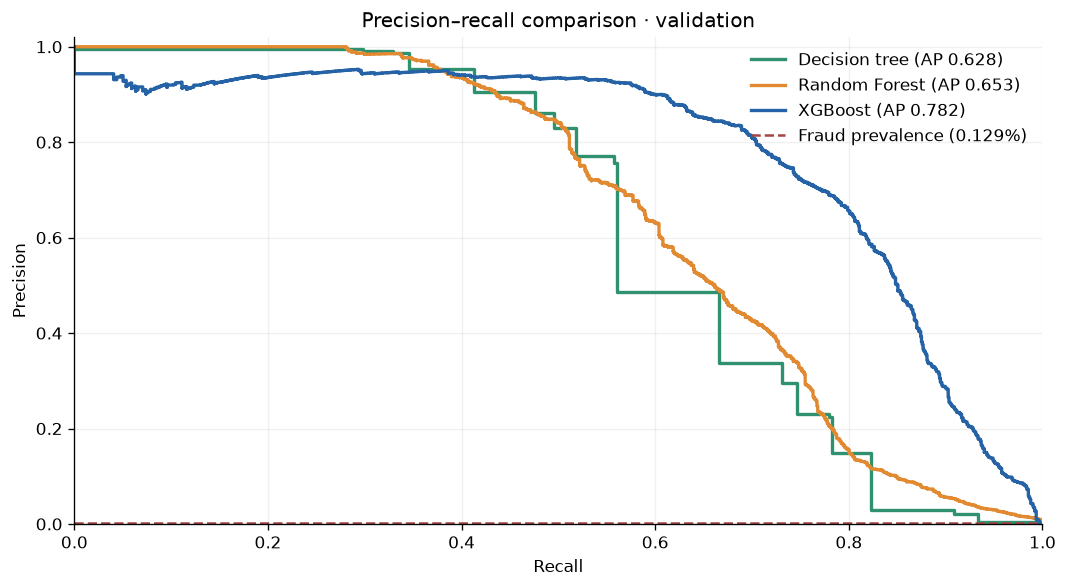

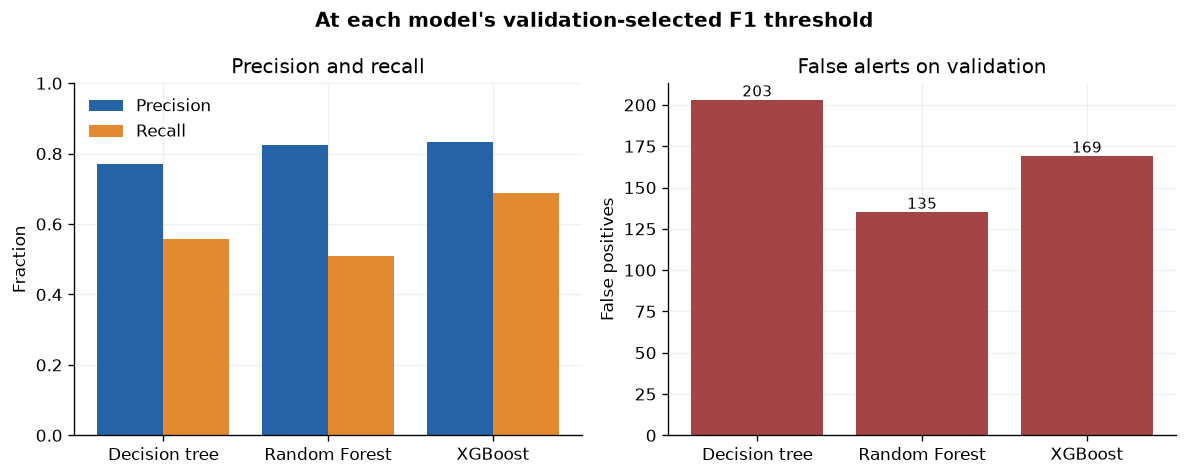

In [6]:
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .18, "axes.axisbelow": True})
fig, ax = plt.subplots(figsize=(9, 5))
for (name, (precision, recall)), color in zip(curves.items(), ["#2f916d", "#e28a32", "#2563a6"]):
    ax.step(recall, precision, where="post", lw=2, color=color, label=f"{name} (AP {average_precision_score(y_val, scores[name]):.3f})")
ax.axhline(y_val.mean(), color="#a54444", ls="--", label=f"Fraud prevalence ({y_val.mean():.3%})")
ax.set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.02), title="Precision–recall comparison · validation")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

selected_rows = results.xs("F1 selected on validation", level="operating_point")
x = np.arange(len(selected_rows))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(x - .2, selected_rows["precision"], .4, color="#2563a6", label="Precision")
axes[0].bar(x + .2, selected_rows["recall"], .4, color="#e28a32", label="Recall")
axes[0].set(title="Precision and recall", ylabel="Fraction", ylim=(0, 1), xticks=x, xticklabels=selected_rows.index)
axes[0].legend(frameon=False)
axes[1].bar(x, selected_rows["false_positives"], color="#a54444")
for i, count in enumerate(selected_rows["false_positives"]):
    axes[1].annotate(f"{count:,}", (i, count), ha="center", va="bottom", fontsize=9)
axes[1].set(title="False alerts on validation", ylabel="False positives", xticks=x, xticklabels=selected_rows.index)
fig.suptitle("At each model's validation-selected F1 threshold", fontweight="bold")
fig.tight_layout()
plt.show()

## 5. Save and verify the checkpoint

The joblib checkpoint contains the preprocessing pipeline, model, threshold, dataset fingerprint, split, feature list and versions. The separate UBJ file is an XGBoost-native copy of the booster: it **does not include preprocessing**, which must be applied exactly as in the pipeline. Rerunning this cell replaces both generated files. Joblib files must be trusted before loading.

In [7]:
checkpoint = {"pipeline": xgb_model, "model_name": "XGBoost", "threshold": selected["XGBoost"],
              "threshold_selection": "max F1 on validation", "features": FEATURES, "seed": SEED,
              "split": SPLIT, "dataset_sha256": actual_sha256, "training_seconds": fit_seconds,
              "validation_average_precision": float(average_precision_score(y_val, scores["XGBoost"])),
              "validation_roc_auc": float(roc_auc_score(y_val, scores["XGBoost"])),
              "python_version": sys.version.split()[0], "numpy_version": np.__version__,
              "pandas_version": pd.__version__, "sklearn_version": sklearn.__version__, "xgboost_version": xgb.__version__}
model_path = ROOT / "models/xgboost_baseline.joblib"
booster_path = ROOT / "models/xgboost_baseline.ubj"
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(checkpoint, model_path, compress=3)
xgb_model.named_steps["classifier"].save_model(booster_path)
reloaded = joblib.load(model_path)
with threadpool_limits(limits=2):
    reloaded_scores = reloaded["pipeline"].predict_proba(X_val.iloc[:128])[:, 1]
np.testing.assert_allclose(reloaded_scores, scores["XGBoost"][:128], rtol=1e-6, atol=1e-7)
booster = xgb.XGBClassifier()
booster.load_model(booster_path)
with threadpool_limits(limits=2):
    transformed = reloaded["pipeline"].named_steps["preprocess"].transform(X_val.iloc[:128])
    native_scores = booster.predict_proba(transformed)[:, 1]
np.testing.assert_allclose(native_scores, reloaded_scores, rtol=1e-6, atol=1e-7)
for path in (model_path, booster_path):
    print(f"Saved and verified: {path.relative_to(ROOT).as_posix()} ({path.stat().st_size:,} bytes)")
print("No test rows were scored.")

Saved and verified: models/xgboost_baseline.joblib (99,980 bytes)
Saved and verified: models/xgboost_baseline.ubj (277,464 bytes)
No test rows were scored.


## Next steps

The remaining proposed models are KNN and the artificial neural network. Compare computational costs, perform feature and imbalance ablations, and run time-based or account-aware checks. The final model and operating threshold should be selected using training/validation data before any final test scoring.